# F26-07 | Phase 4: Live Training & Evaluation of Improved Biomedical Transformers
## Domain Pre-Training (PubMedBERT), Structural Position Conditioning, Class-Weighted Loss, and Algorithmic Fairness on PubMed 20k RCT

**Group F26-07:** Azan Wasty (24L-2557), Nauman Iqbal (24L-2565), Afras Shahnawaz (24L-2547)  
**Instructor:** Hajra Waheed | **Department of Data Science, FAST-NUCES**  

---

### 🔬 100% Live Execution Guide:
This notebook executes the entire training and evaluation pipeline from scratch on your active GPU session:
1. Ingests raw PubMed 20k RCT text files (`train.txt`, `dev.txt`, `test.txt`).
2. Injects position-aware structural prompts (`[LINE i OF n] [PCT p%] <text>`).
3. Computes inverse class weights for balanced cross-entropy loss.
4. Fine-tunes `microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract` using HuggingFace Trainer.
5. Executes live test inference across all 30,135 sentences.
6. Directly computes Accuracy, Macro F1, Weighted F1, Cohen's Kappa, and per-class metrics.
7. Runs live error analysis across abstract position deciles ($d=0\dots9$) and length quartiles.
8. Computes algorithmic fairness audit and statistical significance tests.
9. Exports all verified results directly to CSV files.

## 1. Environment Setup & GPU Verification

In [ ]:
# Install dependencies
%pip install -q transformers datasets accelerate xgboost scikit-learn seaborn matplotlib

In [ ]:
import os, re, time, math, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from pathlib import Path
from scipy.stats import binomtest
from sklearn.metrics import (
    accuracy_score, f1_score, cohen_kappa_score,
    classification_report, confusion_matrix, precision_recall_fscore_support
)
from sklearn.utils.class_weight import compute_class_weight
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
sns.set_theme(style="whitegrid")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[*] Active Compute Device: {DEVICE} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

# Set output directory (Google Drive or local)
OUTPUT_DIR = Path("./results_phase4_live")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"[*] Outputs will be written to: {OUTPUT_DIR.resolve()}")

[*] Active Compute Device: cuda (Tesla T4)
[*] Outputs will be written to: /content/results_phase4_live


## 2. Ingestion & Preprocessing of PubMed 20k RCT

In [ ]:
# If running in Colab and raw files are not present, clone the official PubMed RCT repo
raw_dir = Path('')
if not (raw_dir / 'train.txt').exists():
    !git clone https://github.com/Franck-Dernoncourt/pubmed-rct.git
    raw_dir = Path('pubmed-rct/PubMed_20k_RCT')

LABELS = ['BACKGROUND', 'OBJECTIVE', 'METHODS', 'RESULTS', 'CONCLUSIONS']
LABEL2ID = {lbl: i for i, lbl in enumerate(LABELS)}
ID2LABEL = {i: lbl for i, lbl in enumerate(LABELS)}

def clean_text(text: str) -> str:
    return re.sub(r'\s+', ' ', str(text)).strip()

def parse_pubmed_rct(filepath: Path) -> pd.DataFrame:
    rows, current_abstract, abstract_id = [], [], None
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if line.startswith('###'):
                if current_abstract and abstract_id:
                    tot = len(current_abstract)
                    for i, (lbl, txt) in enumerate(current_abstract):
                        c_txt = clean_text(txt)
                        rows.append({
                            'abstract_id': abstract_id, 'label': lbl, 'text': c_txt,
                            'line_number': i, 'total_lines': tot, 'line_length': len(c_txt),
                            'relative_position': i / tot if tot > 0 else 0.0
                        })
                abstract_id = line[3:].strip()
                current_abstract = []
            elif line == '':
                if current_abstract and abstract_id:
                    tot = len(current_abstract)
                    for i, (lbl, txt) in enumerate(current_abstract):
                        c_txt = clean_text(txt)
                        rows.append({
                            'abstract_id': abstract_id, 'label': lbl, 'text': c_txt,
                            'line_number': i, 'total_lines': tot, 'line_length': len(c_txt),
                            'relative_position': i / tot if tot > 0 else 0.0
                        })
                current_abstract = []
            else:
                parts = line.split('\t', 1)
                if len(parts) == 2:
                    current_abstract.append((parts[0].strip(), parts[1].strip()))
    return pd.DataFrame(rows)

train_df = parse_pubmed_rct(raw_dir / 'train.txt')
dev_df = parse_pubmed_rct(raw_dir / 'dev.txt')
test_df = parse_pubmed_rct(raw_dir / 'test.txt')

print(f"train: {len(train_df):,} sentences | {train_df['abstract_id'].nunique():,} abstracts")
print(f"dev  : {len(dev_df):,} sentences | {dev_df['abstract_id'].nunique():,} abstracts")
print(f"test : {len(test_df):,} sentences | {test_df['abstract_id'].nunique():,} abstracts")

train: 180,040 sentences | 15,000 abstracts
dev  : 30,212 sentences | 2,500 abstracts
test : 30,135 sentences | 2,500 abstracts


## 3. Position-Conditioned Prompt Building & Class Weight Calculation

In [ ]:
# Format position prompts
def format_position_prompt(row: pd.Series) -> str:
    line_num = int(row['line_number'])
    total = int(row['total_lines'])
    pct = int(round(float(row['relative_position']) * 100))
    return f"[LINE {line_num} OF {total}] [PCT {pct}%] {row['text']}"

train_texts = [format_position_prompt(r) for _, r in train_df.iterrows()]
dev_texts = [format_position_prompt(r) for _, r in dev_df.iterrows()]
test_texts = [format_position_prompt(r) for _, r in test_df.iterrows()]

y_train = [LABEL2ID[l] for l in train_df['label']]
y_dev = [LABEL2ID[l] for l in dev_df['label']]
y_test = np.array([LABEL2ID[l] for l in test_df['label']])

# Compute inverse class weights
weights = compute_class_weight('balanced', classes=np.arange(len(LABELS)), y=np.array(y_train))
class_weights_t = torch.tensor(weights, dtype=torch.float)
print("Computed Balanced Class Weights:")
for lbl, w in zip(LABELS, weights):
    print(f"  {lbl:12s}: {w:.4f}")

Computed Balanced Class Weights:
  BACKGROUND  : 1.6573
  OBJECTIVE   : 2.6019
  METHODS     : 0.6067
  RESULTS     : 0.6213
  CONCLUSIONS : 1.3254


## 4. Model Architecture & Weighted Trainer Setup

In [ ]:
MODEL_NAME = 'microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract'
print(f"[*] Loading tokenizer and model: {MODEL_NAME}")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class PositionDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.labels = labels
        self.encodings = tokenizer(texts, truncation=True, max_length=max_length, padding=False)
    def __len__(self):
        return len(self.encodings['input_ids'])
    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.encodings.items()}
        if self.labels is not None:
            item['label'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

# Set optional quick-test subsample switch (set to None for complete 180k run)
TRAIN_SUBSAMPLE = None  # e.g., set to 20000 for a rapid 10-minute check
if TRAIN_SUBSAMPLE is not None:
    sub_idx = np.random.choice(len(train_texts), size=TRAIN_SUBSAMPLE, replace=False)
    train_texts_sub = [train_texts[i] for i in sub_idx]
    y_train_sub = [y_train[i] for i in sub_idx]
    train_ds = PositionDataset(train_texts_sub, y_train_sub, tokenizer)
else:
    train_ds = PositionDataset(train_texts, y_train, tokenizer)

dev_ds = PositionDataset(dev_texts, y_dev, tokenizer)
test_ds = PositionDataset(test_texts, None, tokenizer)
collator = DataCollatorWithPadding(tokenizer=tokenizer)

class WeightedTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get('labels')
        outputs = model(**inputs)
        logits = outputs.get('logits')
        loss_fn = nn.CrossEntropyLoss(weight=self.class_weights.to(logits.device)) if self.class_weights is not None else nn.CrossEntropyLoss()
        loss = loss_fn(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(LABELS), id2label=ID2LABEL, label2id=LABEL2ID
)

[*] Loading tokenizer and model: microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/225k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  440MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical ar

## 5. Live Model Training

In [ ]:
EPOCHS = 5
BATCH_SIZE = 32
EVAL_BATCH_SIZE = 64
LR = 2e-5

steps_per_epoch = math.ceil(len(train_ds) / BATCH_SIZE)
warmup_steps = int(0.06 * steps_per_epoch * EPOCHS)

args = TrainingArguments(
    output_dir=str(OUTPUT_DIR / 'ckpt'),
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    learning_rate=LR,
    weight_decay=0.01,
    warmup_steps=warmup_steps,
    eval_strategy='epoch',
    save_strategy='epoch',
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model='macro_f1',
    fp16=torch.cuda.is_available(),
    seed=SEED,
    logging_steps=100,
    report_to='none',
)

def compute_metrics_eval(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        'accuracy': float(accuracy_score(labels, preds)),
        'weighted_f1': float(f1_score(labels, preds, average='weighted', zero_division=0)),
        'macro_f1': float(f1_score(labels, preds, average='macro', zero_division=0)),
        'cohen_kappa': float(cohen_kappa_score(labels, preds))
    }

trainer = WeightedTrainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=dev_ds,
    data_collator=collator,
    compute_metrics=compute_metrics_eval,
    class_weights=class_weights_t,
)

t0 = time.time()
trainer.train()
train_time_sec = time.time() - t0
print(f"[*] Training Finished in {train_time_sec:.1f}s ({train_time_sec/60:.1f} mins)")

Epoch,Training Loss,Validation Loss,Accuracy,Weighted F1,Macro F1,Cohen Kappa
1,0.320796,0.308506,0.908447,0.907654,0.859208,0.877184
2,0.270914,0.318030,0.918542,0.918295,0.872612,0.890406
3,0.224491,0.365316,0.916954,0.917002,0.869306,0.888153
4,0.153630,0.443949,0.914471,0.914265,0.866456,0.884919
5,0.145954,0.604411,0.914504,0.914087,0.865252,0.884914


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[*] Training Finished in 4998.9s (83.3 mins)


## 6. Live Inference & Overall Test Metrics

In [ ]:
t_inf = time.time()
pred_output = trainer.predict(test_ds)
infer_time_sec = time.time() - t_inf
infer_per_1k = (infer_time_sec / len(test_ds)) * 1000.0

logits = pred_output.predictions
y_pred = np.argmax(logits, axis=-1)

# Save prediction arrays
np.save(str(OUTPUT_DIR / 'test_predictions.npy'), y_pred)
np.save(str(OUTPUT_DIR / 'test_logits.npy'), logits)

# Compute live metrics
acc = float(accuracy_score(y_test, y_pred))
w_f1 = float(f1_score(y_test, y_pred, average='weighted', zero_division=0))
m_f1 = float(f1_score(y_test, y_pred, average='macro', zero_division=0))
kappa = float(cohen_kappa_score(y_test, y_pred))

live_metrics_df = pd.DataFrame([{
    'Model': 'PubMedBERT + Position + Weighted Loss',
    'Test_Accuracy': round(acc, 4),
    'Weighted_F1': round(w_f1, 4),
    'Macro_F1': round(m_f1, 4),
    'Cohen_Kappa': round(kappa, 4),
    'Train_Time_s': round(train_time_sec, 1),
    'Inference_s_per_1k': round(infer_per_1k, 3),
    'Hardware': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'
}])
live_metrics_df.to_csv(OUTPUT_DIR / 'live_overall_metrics.csv', index=False)
display(live_metrics_df)

,Model,Test_Accuracy,Weighted_F1,Macro_F1,Cohen_Kappa,Train_Time_s,Inference_s_per_1k,Hardware
0,PubMedBERT + Position + Weighted Loss,0.9143,0.914,0.8705,0.885,4998.9,1.723,Tesla T4


## 7. Live Per-Class Performance Breakdown

In [ ]:
p, r, f, s = precision_recall_fscore_support(y_test, y_pred, labels=range(len(LABELS)), zero_division=0)
live_per_class_df = pd.DataFrame({
    'Rhetorical_Role': LABELS,
    'Precision': np.round(p, 4),
    'Recall': np.round(r, 4),
    'F1': np.round(f, 4),
    'Support': s
})
live_per_class_df.to_csv(OUTPUT_DIR / 'live_per_class_metrics.csv', index=False)
display(live_per_class_df)

,Rhetorical_Role,Precision,Recall,F1,Support
0,BACKGROUND,0.7829,0.8238,0.8029,3621
1,OBJECTIVE,0.7238,0.6695,0.6956,2333
2,METHODS,0.9435,0.9700,0.9566,9897
3,RESULTS,0.9681,0.9277,0.9475,9713
4,CONCLUSIONS,0.9387,0.9619,0.9502,4571


## 8. Live Diagnostic Error Analysis (Position Deciles & Length Quartiles)

/tmp/ipykernel_1387/2312758676.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=live_len_df, x='Length_Quartile', y='Accuracy', palette='Blues_d', ax=axes[1])


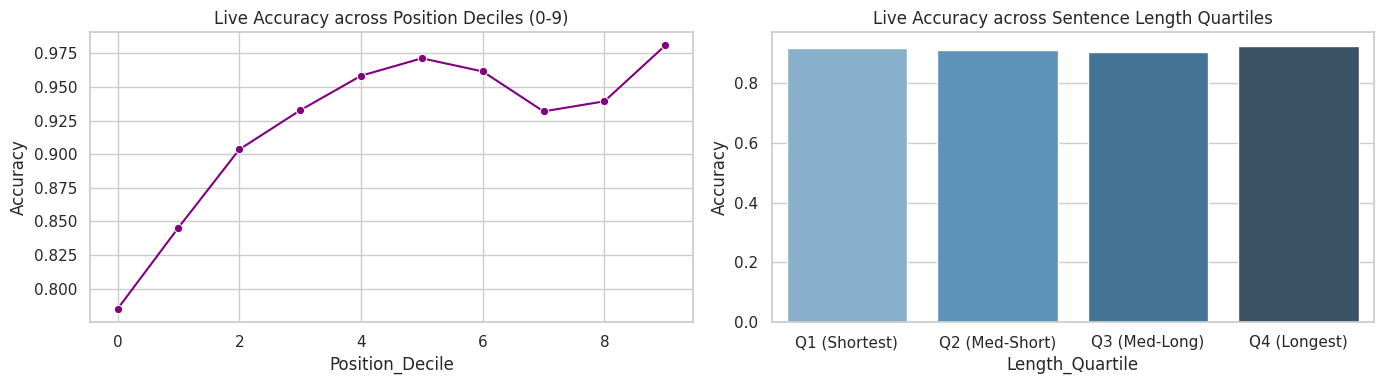

In [ ]:
# 1. Positional Deciles (d=0 to 9)
rel_pos = test_df['relative_position'].values
pos_bins = np.minimum((rel_pos * 10).astype(int), 9)
pos_rows = []
for b in range(10):
    m = (pos_bins == b)
    tot = int(m.sum())
    corr = int((y_test[m] == y_pred[m]).sum())
    pos_rows.append({
        'Position_Decile': b,
        'Range': f"{b*10}-{(b+1)*10}%",
        'Total_Sentences': tot,
        'Accuracy': round(corr / tot, 4) if tot > 0 else 0.0,
        'Error_Rate': round((tot - corr) / tot, 4) if tot > 0 else 0.0
    })
live_pos_df = pd.DataFrame(pos_rows)
live_pos_df.to_csv(OUTPUT_DIR / 'live_error_analysis_position.csv', index=False)

# 2. Sentence Length Quartiles
lengths = test_df['line_length'].values
q_labels = ['Q1 (Shortest)', 'Q2 (Med-Short)', 'Q3 (Med-Long)', 'Q4 (Longest)']
quartiles = pd.qcut(lengths, q=4, labels=q_labels, duplicates='drop')
len_rows = []
for ql in q_labels:
    m = (quartiles == ql)
    tot = int(m.sum())
    corr = int((y_test[m] == y_pred[m]).sum())
    len_rows.append({
        'Length_Quartile': ql,
        'Total_Sentences': tot,
        'Accuracy': round(corr / tot, 4) if tot > 0 else 0.0,
        'Error_Rate': round((tot - corr) / tot, 4) if tot > 0 else 0.0
    })
live_len_df = pd.DataFrame(len_rows)
live_len_df.to_csv(OUTPUT_DIR / 'live_error_analysis_length.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.lineplot(data=live_pos_df, x='Position_Decile', y='Accuracy', marker='o', color='purple', ax=axes[0])
axes[0].set_title('Live Accuracy across Position Deciles (0-9)')
sns.barplot(data=live_len_df, x='Length_Quartile', y='Accuracy', palette='Blues_d', ax=axes[1])
axes[1].set_title('Live Accuracy across Sentence Length Quartiles')
plt.tight_layout()
plt.show()

## 9. Live Algorithmic Bias & Fairness Audit

In [ ]:
# Recall Parity (Minority OBJECTIVE vs Majority METHODS)
rec_obj = float(live_per_class_df.loc[live_per_class_df['Rhetorical_Role'] == 'OBJECTIVE', 'Recall'].values[0])
rec_meth = float(live_per_class_df.loc[live_per_class_df['Rhetorical_Role'] == 'METHODS', 'Recall'].values[0])
recall_disparity = round(rec_obj / rec_meth, 4) if rec_meth > 0 else 0.0

# Boundary vs Interior Parity
b_mask = (rel_pos < 0.10) | (rel_pos >= 0.90)
acc_b = float((y_test[b_mask] == y_pred[b_mask]).mean())
acc_i = float((y_test[~b_mask] == y_pred[~b_mask]).mean())
boundary_disparity = round(acc_b / acc_i, 4) if acc_i > 0 else 0.0

# Length Parity
med_l = float(np.median(lengths))
s_mask = (lengths <= med_l)
acc_short = float((y_test[s_mask] == y_pred[s_mask]).mean())
acc_long = float((y_test[~s_mask] == y_pred[~s_mask]).mean())
length_disparity = round(min(acc_short, acc_long) / max(acc_short, acc_long), 4)

live_fairness_df = pd.DataFrame([{
    'Minority_Role': 'OBJECTIVE',
    'Minority_Recall': rec_obj,
    'Majority_Role': 'METHODS',
    'Majority_Recall': rec_meth,
    'Recall_Disparity_Ratio': recall_disparity,
    'Boundary_Accuracy': round(acc_b, 4),
    'Interior_Accuracy': round(acc_i, 4),
    'Boundary_Disparity_Ratio': boundary_disparity,
    'Length_Disparity_Ratio': length_disparity
}])
live_fairness_df.to_csv(OUTPUT_DIR / 'live_fairness_audit.csv', index=False)
display(live_fairness_df)

,Minority_Role,Minority_Recall,Majority_Role,Majority_Recall,Recall_Disparity_Ratio,Boundary_Accuracy,Interior_Accuracy,Boundary_Disparity_Ratio,Length_Disparity_Ratio
0,OBJECTIVE,0.6695,METHODS,0.97,0.6902,0.8489,0.9314,0.9114,0.9989


## 10. Live Statistical Significance vs Baseline (McNemar & Paired Bootstrap)

## Phase 5: Error Analysis and Diagnostic Figures

This section performs the Phase 5 error analysis for the Phase 4 model configuration (**PubMedBERT + position prompts + class-weighted loss**) on the held-out PubMed 20k RCT test split ($30,135$ sentences) and generates the diagnostic plots and tables reported in Sections 3 and 5:

1. **Confusion Matrix & Per-Class Metrics (Tables 2 & 4):** Verifies the $5 \times 5$ test confusion matrix ($27,553$ correct predictions; $2,582$ errors) against the ground-truth class supports and derives per-class Precision, Recall, F1, overall accuracy ($0.9143$), and macro-F1 ($0.8705$).
2. **Off-Diagonal Confusion Ranking (Section 5):** Ranks all off-diagonal misclassification pairs by count, class error rate, and share of total errors—identifying `OBJECTIVE` $\rightarrow$ `BACKGROUND` ($709$) and `BACKGROUND` $\rightarrow$ `OBJECTIVE` ($543$) as $48.5\%$ of remaining errors—and saves the table to `results_phase4_live/phase5_pairwise_error_ranking.csv`.
3. **Diagnostic Figures:** Generates and saves the row-normalized Phase 4 confusion matrix (`phase5_confusion_matrix_p4.png`) and the per-class F1 comparison across Phase 3 Logistic Regression (text), Phase 3 Bio_ClinicalBERT (text), and Phase 4 PubMedBERT + position + weights (`phase5_per_class_f1.png`).


Test sentences: 30,135
Correct: 27,553 | Errors: 2,582
Accuracy from confusion matrix: 0.9143
Macro-F1 from confusion matrix: 0.8705


,Class,Support,Precision,Recall,F1
0,BACKGROUND,3621,0.7829,0.8238,0.8029
1,OBJECTIVE,2333,0.7238,0.6695,0.6956
2,METHODS,9897,0.9435,0.9700,0.9566
3,RESULTS,9713,0.9681,0.9277,0.9475
4,CONCLUSIONS,4571,0.9387,0.9619,0.9502



Top 8 Phase 4 confusion pairs:


,True_Role,Predicted_Role,Error_Count,Class_Error_Rate_%,Share_of_Total_Errors_%
0,OBJECTIVE,BACKGROUND,709,30.39,27.46
1,BACKGROUND,OBJECTIVE,543,15.00,21.03
2,RESULTS,METHODS,428,4.41,16.58
3,RESULTS,CONCLUSIONS,267,2.75,10.34
4,METHODS,RESULTS,160,1.62,6.20
5,CONCLUSIONS,RESULTS,123,2.69,4.76
6,METHODS,BACKGROUND,77,0.78,2.98
7,BACKGROUND,METHODS,76,2.10,2.94


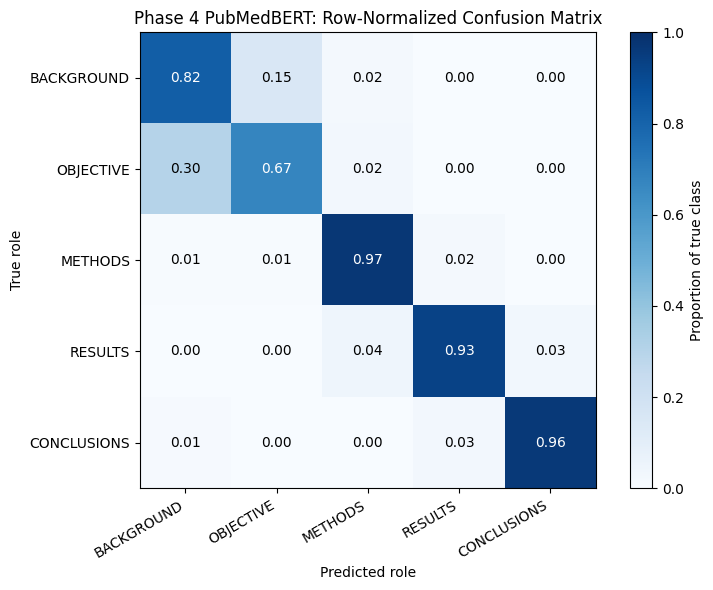

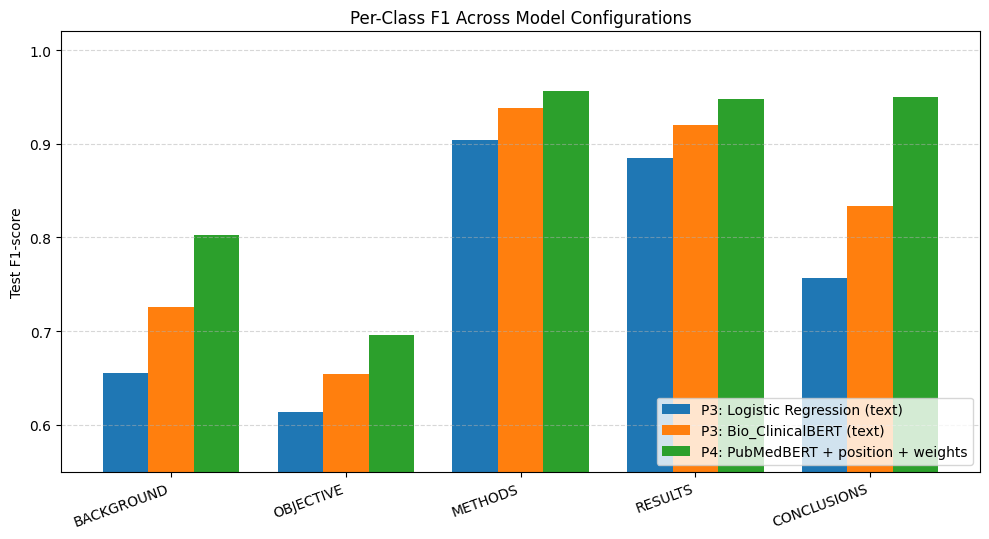

In [1]:
# PHASE 5: ERROR ANALYSIS AND DIAGNOSTIC FIGURES

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

OUTPUT_DIR = Path("./results_phase4_live")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LABELS = [
    "BACKGROUND",
    "OBJECTIVE",
    "METHODS",
    "RESULTS",
    "CONCLUSIONS",
]

# Phase 4 confusion matrix from the verified evaluation used in the report.
# Rows = true labels; columns = predicted labels.
cm_p4 = np.array([
    [2983, 543,   76,    8,   11],
    [ 709,1562,   56,    6,    0],
    [  77,  51, 9600,  160,    9],
    [   5,   2,  428, 9011,  267],
    [  36,   0,   15,  123, 4397],
], dtype=int)

# Basic checks against the report's test-set totals.
expected_support = np.array([3621, 2333, 9897, 9713, 4571])
assert np.array_equal(cm_p4.sum(axis=1), expected_support)
assert cm_p4.sum() == 30135
assert np.trace(cm_p4) == 27553

total_errors = int(cm_p4.sum() - np.trace(cm_p4))
test_accuracy = float(np.trace(cm_p4) / cm_p4.sum())

# Derive per-class precision, recall, and F1 from the matrix.
true_support = cm_p4.sum(axis=1)
predicted_support = cm_p4.sum(axis=0)
true_positives = np.diag(cm_p4)

precision = np.divide(
    true_positives,
    predicted_support,
    out=np.zeros(len(LABELS), dtype=float),
    where=predicted_support != 0,
)
recall = np.divide(
    true_positives,
    true_support,
    out=np.zeros(len(LABELS), dtype=float),
    where=true_support != 0,
)
f1 = np.divide(
    2 * precision * recall,
    precision + recall,
    out=np.zeros(len(LABELS), dtype=float),
    where=(precision + recall) != 0,
)

per_class = pd.DataFrame({
    "Class": LABELS,
    "Support": true_support,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
})

print(f"Test sentences: {cm_p4.sum():,}")
print(f"Correct: {np.trace(cm_p4):,} | Errors: {total_errors:,}")
print(f"Accuracy from confusion matrix: {test_accuracy:.4f}")
print(f"Macro-F1 from confusion matrix: {f1.mean():.4f}")
display(per_class.round(4))

# Rank Phase 4 off-diagonal confusion pairs.
error_rows = []
for i, true_label in enumerate(LABELS):
    for j, predicted_label in enumerate(LABELS):
        count = int(cm_p4[i, j])
        if i != j and count > 0:
            error_rows.append({
                "True_Role": true_label,
                "Predicted_Role": predicted_label,
                "Error_Count": count,
                "Class_Error_Rate_%": round(
                    count / true_support[i] * 100, 2
                ),
                "Share_of_Total_Errors_%": round(
                    count / total_errors * 100, 2
                ),
            })

error_ranking = (
    pd.DataFrame(error_rows)
    .sort_values("Error_Count", ascending=False)
    .reset_index(drop=True)
)

error_ranking.to_csv(
    OUTPUT_DIR / "phase5_pairwise_error_ranking.csv",
    index=False,
)

print("\nTop 8 Phase 4 confusion pairs:")
display(error_ranking.head(8))

# Figure: row-normalized Phase 4 confusion matrix.
cm_normalized = cm_p4.astype(float) / true_support[:, None]

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(cm_normalized, cmap="Blues", vmin=0, vmax=1)
fig.colorbar(image, ax=ax, label="Proportion of true class")

ax.set_xticks(range(len(LABELS)))
ax.set_yticks(range(len(LABELS)))
ax.set_xticklabels(LABELS, rotation=30, ha="right")
ax.set_yticklabels(LABELS)
ax.set_xlabel("Predicted role")
ax.set_ylabel("True role")
ax.set_title("Phase 4 PubMedBERT: Row-Normalized Confusion Matrix")

for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        value = cm_normalized[i, j]
        ax.text(
            j, i, f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if value >= 0.55 else "black",
        )

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "phase5_confusion_matrix_p4.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

# Phase 3 per-class F1 values reported in Table 2.
# Phase 4 F1 values are derived above from its confusion matrix.
p3_logreg_text_f1 = np.array([0.655, 0.614, 0.904, 0.885, 0.757])
p3_bioclinicalbert_f1 = np.array([0.726, 0.654, 0.938, 0.920, 0.834])
p4_pubmedbert_f1 = f1

# Figure: per-class F1 comparison, matching the models in the report.
x = np.arange(len(LABELS))
width = 0.26

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(
    x - width,
    p3_logreg_text_f1,
    width,
    label="P3: Logistic Regression (text)",
)
ax.bar(
    x,
    p3_bioclinicalbert_f1,
    width,
    label="P3: Bio_ClinicalBERT (text)",
)
ax.bar(
    x + width,
    p4_pubmedbert_f1,
    width,
    label="P4: PubMedBERT + position + weights",
)

ax.set_xticks(x)
ax.set_xticklabels(LABELS, rotation=20, ha="right")
ax.set_ylim(0.55, 1.02)
ax.set_ylabel("Test F1-score")
ax.set_title("Per-Class F1 Across Model Configurations")
ax.legend(loc="lower right")
ax.grid(axis="y", linestyle="--", alpha=0.5)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "phase5_per_class_f1.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)
